In [6]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import astropy.units as u
import numpy as np
import gc
import lsst.daf.butler as DafButler
from lsst_efd_client import EfdClient 
import lsst.summit.utils.plotting as splot
from astropy.time import Time, TimeDelta





In [7]:
butler = DafButler.Butler('/repo/embargo', collections=["LSSTCam/runs/nightlyValidation"], instrument='LSSTCam')
registry = butler.registry
visit = 2025050700642 #429 433
client =  EfdClient('usdf_efd')

info=butler.get('raw.visitInfo', detector=94, exposure=visit)  #change exposure to visit for raw or post_isr
print(info)
#Dref = list(registry.queryDatasets('raw', where=f"visit={visit} and detector=65"))  #corner dtectors 188, 161, 65, 20, 0, 27, 123, 168
#dataImgs = [butler.get(dr) for dr in Dref]
##g=Dref[0].dataId['group'][:-2]
#header = {key: val for key, val in dataImgs[0].getMetadata().items()}

#print(Dref)
#_=splot.plot(dataImgs[0], stretch='asinh',percentile=98,cmap='plasma')


VisitInfo(exposureTime=30, darkTime=30.9343, date=2025-05-08T07:46:38.703895597, UT1=nan, ERA=5.97912 rad, boresightRaDec=(212.8490123532, -16.6633321263), boresightAzAlt=(nan, +nan), boresightAirmass=nan, boresightRotAngle=0.445659 rad, rotType=0, observatory=nanN, nanE  nan, weather=Weather(3.675, 73880, 44.75), instrumentLabel='LSSTCam', id=2025050700642, focusZ=-2.28509, observationType='acq', scienceProgram='BLOCK-T393', observationReason='infocus_sitcom-1489', object='UNKNOWN', hasSimulatedContent=false)


Visit:   2025042200239
Exposure:  15.0
Visit:   2025042200240
Exposure:  15.0
Visit:   2025042200241
Exposure:  15.0
Visit:   2025042200242
Exposure:  15.0
Visit:   2025042200243
Exposure:  15.0
Visit:   2025042200244
Exposure:  15.0
Visit:   2025042200245
Exposure:  15.0
Visit:   2025042200246
Exposure:  15.0
Visit:   2025042200247
Exposure:  15.0
Visit:   2025042200248
Exposure:  15.0
Visit:   2025042200249
Exposure:  15.0
<class 'pandas.core.frame.DataFrame'>


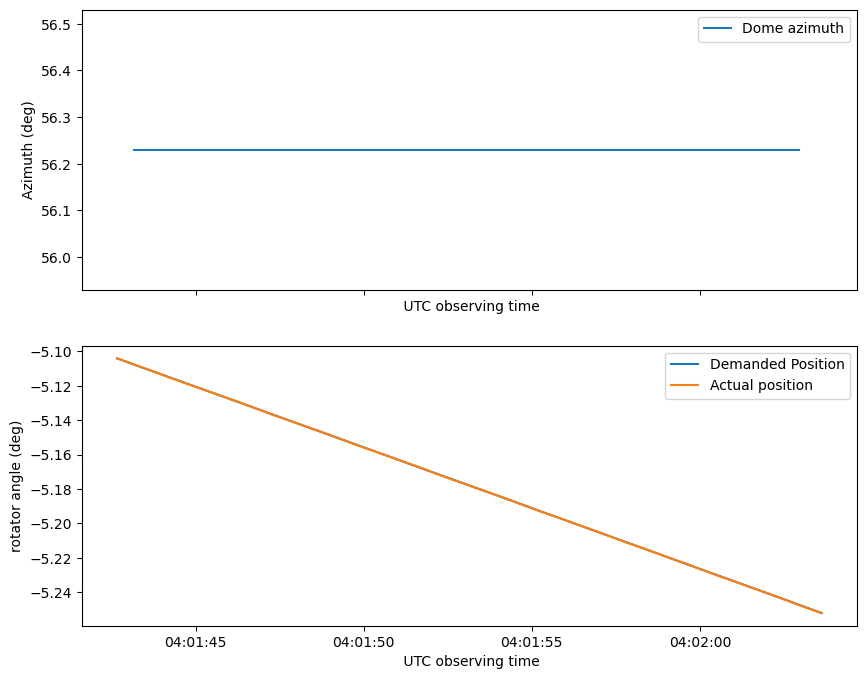

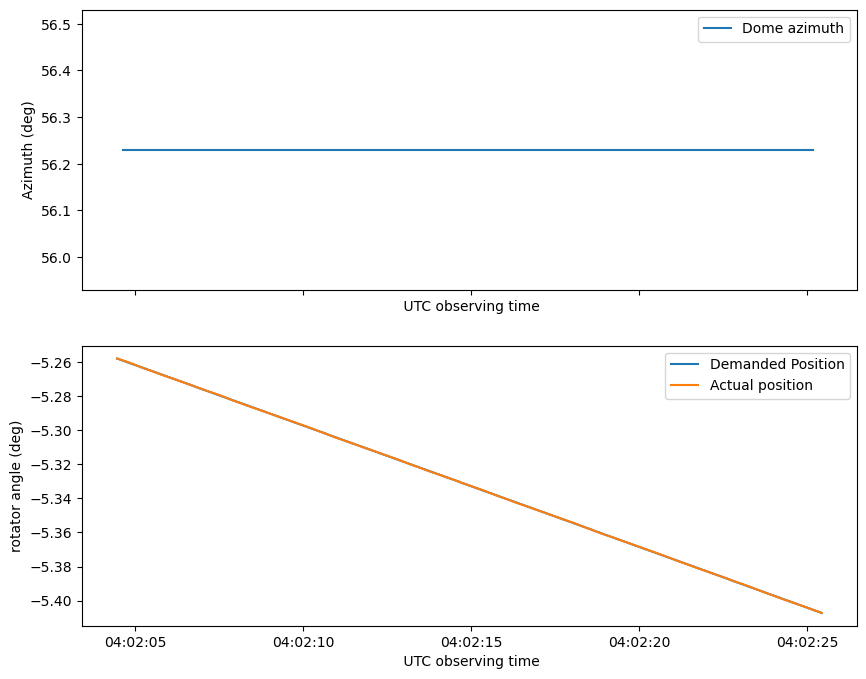

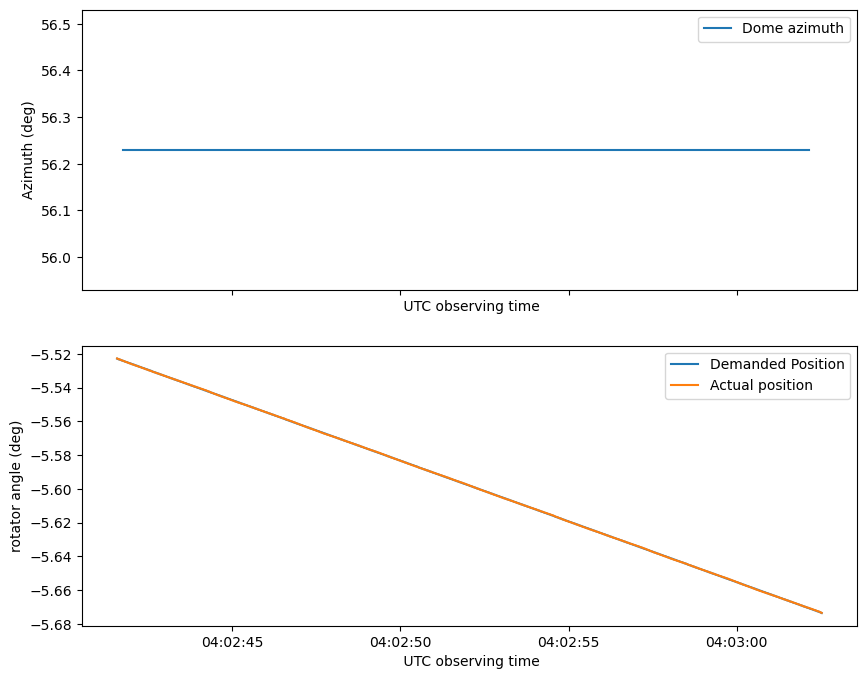

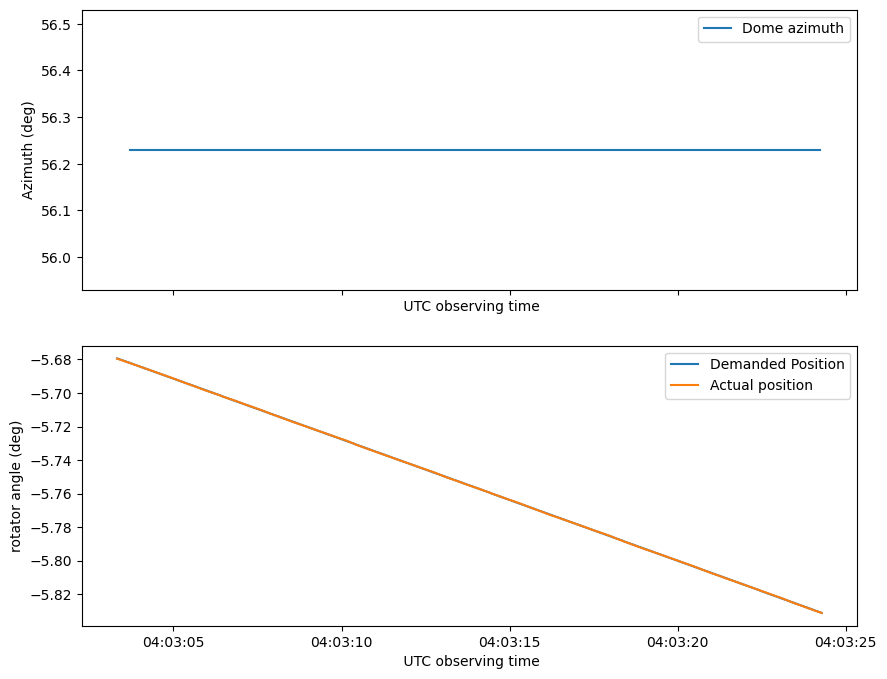

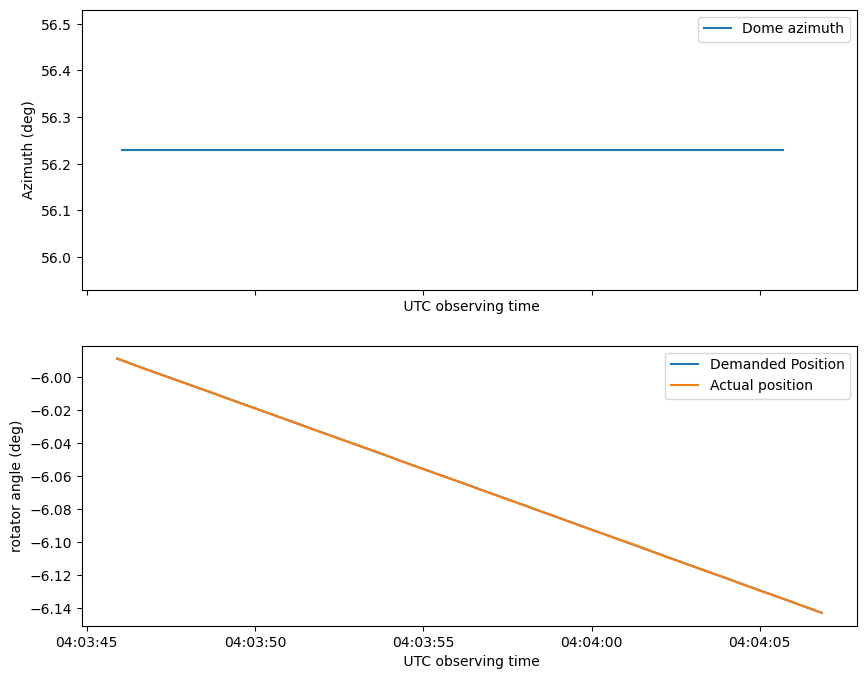

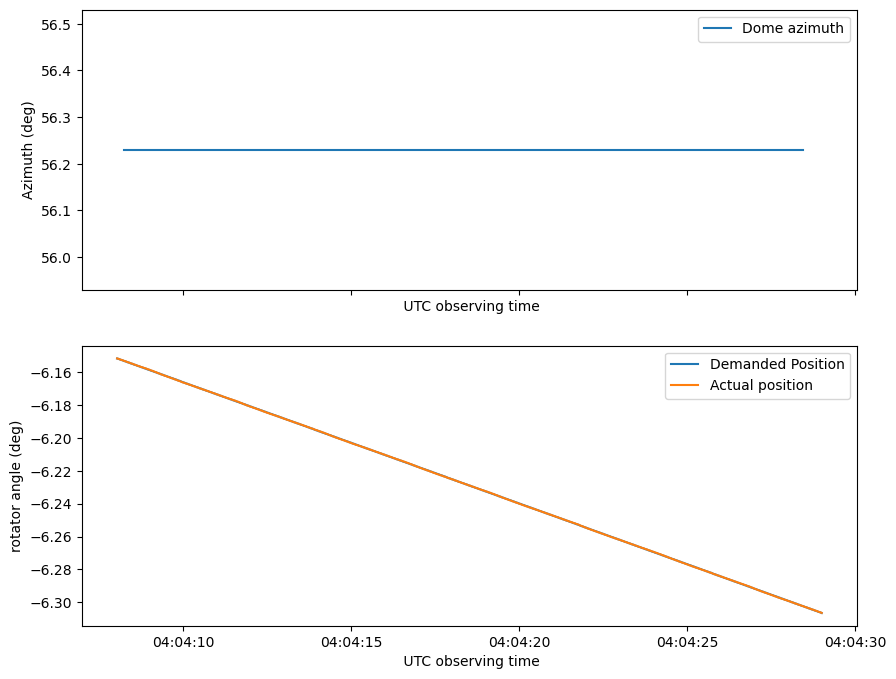

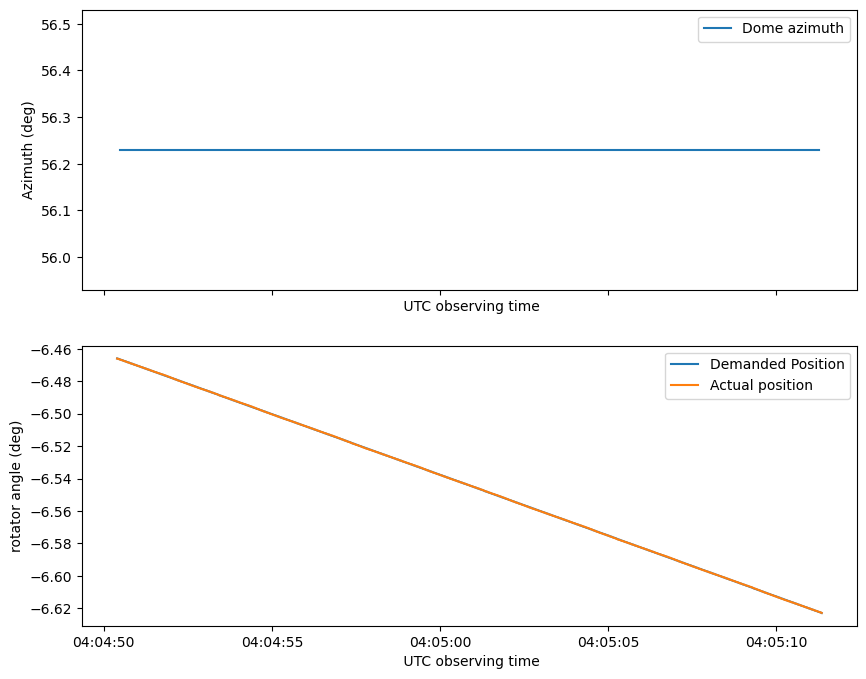

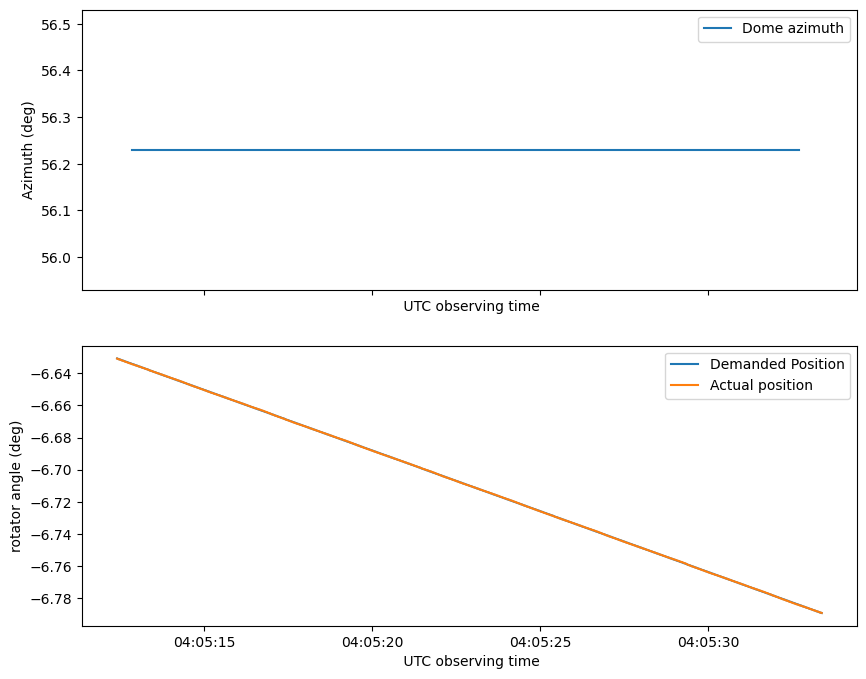

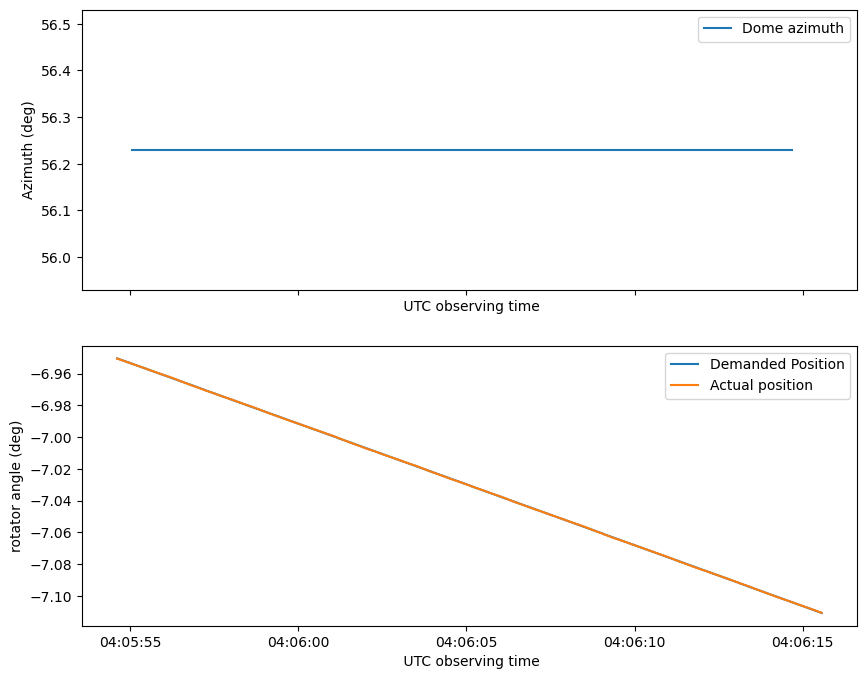

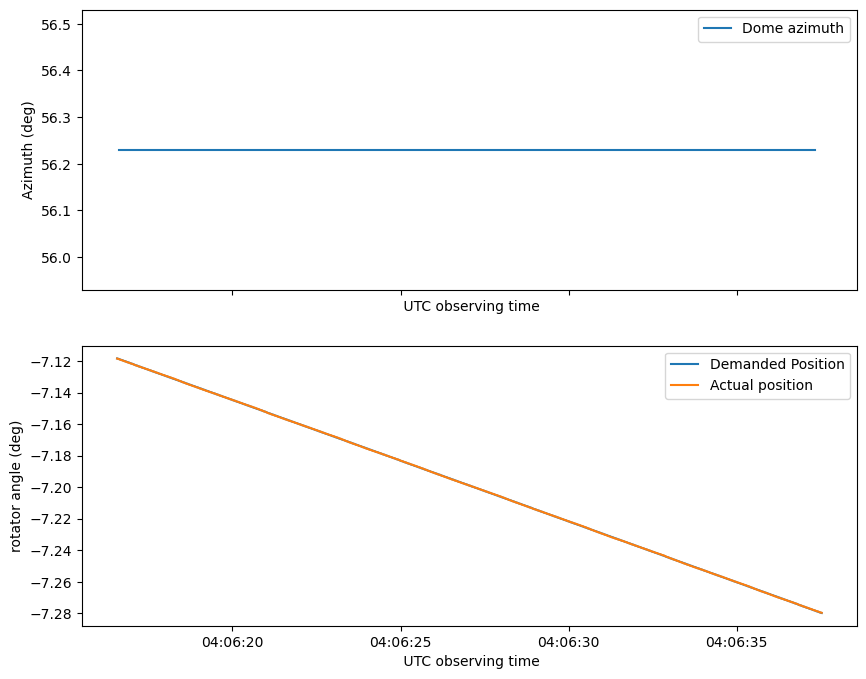

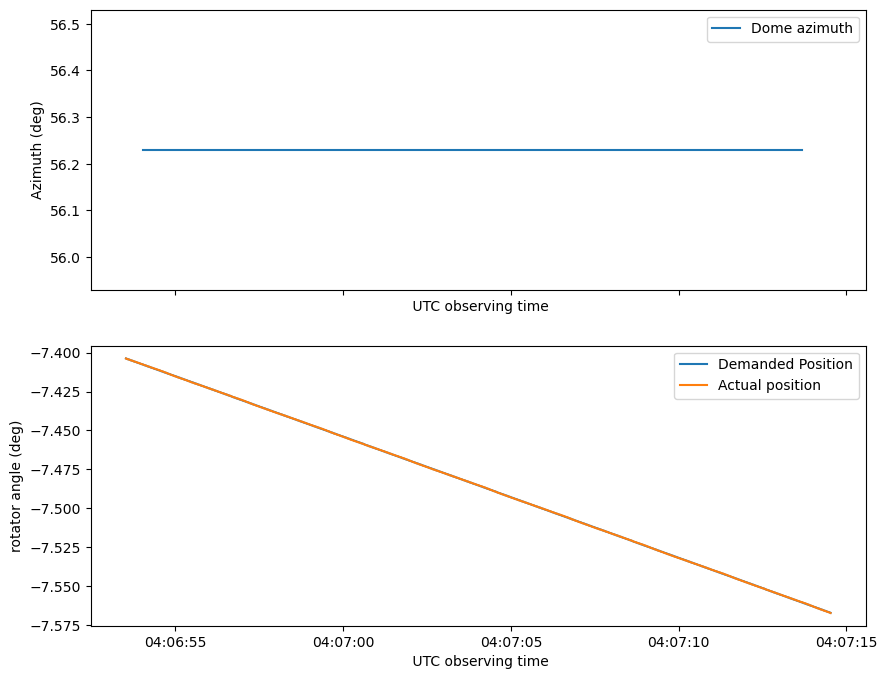

In [10]:
day_obs=20250422
client =  EfdClient('usdf_efd')

for seq in range(239,250):
    visit=day_obs*100000+seq
    print('Visit:  ',visit)
    
    try:
        info=butler.get('raw.visitInfo', detector=94, exposure=visit)  #change exposure to visit for raw or post_isr
        st_time=str(info.date).split('"')[1]
        exposure=float(info.exposureTime)
        time_start = Time(st_time, scale="utc", format="isot")-TimeDelta(3, format='sec')
        time_end   = time_start+TimeDelta(exposure+6, format='sec')
    except :
        print('NO DATA FOR THAT VISIT')
        continue
    
    Dome_azimuth=(await client.select_time_series(
        "lsst.sal.MTDome.azimuth",
        fields=['positionActual'],
        start=time_start,
        end=time_end
    ))

    rotator_ang=(await client.select_time_series(
        "lsst.sal.MTRotator.rotation",
        fields=['actualPosition', 'demandPosition'],
        start=time_start,
        end=time_end
    ))
    
    Az_max=float(Dome_azimuth.max().iloc[0])
    Az_min=float(Dome_azimuth.min().iloc[0])
    

    print('Exposure: ' , exposure)

    fig, axs = plt.subplots(2, 1, figsize=(10, 8), sharex=True, sharey=False)
    
    
#    print(f"ROTATION DETECTED FOR VISIT {visit}")
    axs[0].plot(Dome_azimuth, label='Dome azimuth')
    axs[0].set_xlabel(' UTC observing time')
    axs[0].set_ylabel('Azimuth (deg)')
    axs[0].set_ylim(Az_min-0.3,Az_max+0.3)
    axs[0].legend()
    axs[1].plot(rotator_ang['demandPosition'],label='Demanded Position')
    axs[1].plot(rotator_ang['actualPosition'],label='Actual position')    
    axs[1].set_xlabel(' UTC observing time')
    axs[1].set_ylabel('rotator angle (deg)')
    plt.legend()
  #  plt.show()


measured_forces = await client.select_time_series(
    "lsst.sal.MTM1M3.forceActuatorData",
    fields = ["primatyCylinderFollowingError", "timestamp"],
    start  = time_start,
    end    = time_end
)

print(type(measured_forces))


In [ ]:


day_obs=20250505
client =  EfdClient('usdf_efd')
time_start = Time(g, scale="utc", format="isot")-TimeDelta(5, format='sec')
time_end   = time_start+TimeDelta(40, format='sec')

for seq in range(500, 600):
    visit=day_obs*100000+seq
    print(visit)
    
    try:
        info=butler.get('raw.visitInfo', detector=94, exposure=visit)  #change exposure to visit for raw or post_isr
        st_time=str(info.date).split('"')[1]
        exposure=float(info.exposureTime)
    except :
        print('NO DATA FOR THAT VISIT')
        continue
    
    #g=Dref[0].dataId['group'].split('#')[0]
    print(st_time)   
    time_start = Time(st_time, scale="utc", format="isot")#-TimeDelta(3, format='sec')
    
    time_end   = time_start+TimeDelta(exposure, format='sec')
    print('Exposure: ' , exposure)
    rotator_ang=(await client.select_time_series(
        "lsst.sal.MTRotator.rotation",
        fields=['actualPosition', 'demandPosition'],
        start=time_start,
        end=time_end
    ))
    plt.figure(figsize=(10,4))
    plt.plot(rotator_ang['demandPosition'])
    plt.plot(rotator_ang['actualPosition'])

    plt.xlabel(' UTC observing time')
    plt.ylabel('Rotator angle (deg)')
    plt.show()
    plt.close()

In [5]:
measured_forces = await client.select_time_series(
    "lsst.sal.MTM1M3.forceActuatorData",
    [follow, "timestamp"],
    t_start,
    t_end
)

NameError: name 'follow' is not defined